# 12 · Group descriptions: the everyday words the official names lack

**The question this step answers:** the shortlist compares an account name with the 190 standard groups' *official* names. Bookkeepers don't write official names. Does giving each group a short description, plus the ledger words people actually use, put the right group on the shortlist more often, without hurting the rest?

**Where it sits in the pipeline:** it changes the shortlist (notebook 07), so it changes the ceiling of every method after it. If the right group is not among the 10 candidates, no method can pick it.

**The code:**
- `src/d1/mapper/descriptions.py` asks the description model for the descriptions, checks them and freezes them in `data/frozen/group_descriptions/`;
- `prompts/describe_groups.md` is the exact prompt;
- `src/d1/mapper/retrieve.py` embeds the groups with them (`group_text`);
- `python -m d1.evaluation.select_embedder --group-text descriptions|average` reran the three-model comparison of notebook 08. This notebook reads its saved results, so it runs in seconds, without loading a model.

*Re-run on 2026-11-06 after the account names were cleaned of company, bank and brand names (notebook 04, section 3b); every number below is from that run.*

In [1]:
import json
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import (
    BLUE_RAMP, COLORS, INK, INK_2, LANGUAGE_COLORS, MUTED, SINGLE, SOURCE_COLORS, SURFACE, apply_style, pct, short,
)

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

from d1.evaluation.plotting import GRID
from d1.evaluation.embedding_analysis import company_bootstrap_ci, load_rows, paired_difference, recall_curve
from d1.mapper.calibrate import Calibrator, choose_threshold, cross_fit_probs, stricter_threshold
from d1.mapper.descriptions import load_entries
from d1.mapper.retrieve import standard_text

K = config.models.mapping.candidates_k
VARIANTS = ["names", "average", "descriptions"]  # from no description to description only
VARIANT_COLORS = {"names": BLUE_RAMP[1], "average": BLUE_RAMP[2], "descriptions": BLUE_RAMP[4]}
files = {"names": "embedding_selection_rows.csv", "average": "embedding_selection_average_rows.csv",
         "descriptions": "embedding_selection_descriptions_rows.csv"}
rows = pd.concat([load_rows(REPO_ROOT / "reports" / f).assign(variant=v) for v, f in files.items()], ignore_index=True)
rows["model_short"] = rows["model"].map(short)
models = list(dict.fromkeys(rows["model"]))
entries = load_entries(config.data.frozen_descriptions_dir, chart)
print(f"{len(entries)} group descriptions; {rows.account_id.nunique()} dev accounts x {len(models)} models x {len(VARIANTS)} group texts")

190 group descriptions; 3500 dev accounts x 3 models x 3 group texts


## 1. One group, before and after

Group **620** is where salaries go. This is the text the embedding model compares an account with, names only and then with the description added:

In [2]:
a = by_code["620"]
print("names only:\n  " + standard_text(a))
print("\nwith the description:\n  " + standard_text(a, entries["620"].text()))

names only:
  Remuneration and Direct Social Benefits | Bezoldigingen en rechtstreekse sociale voordelen | Rémunérations et avantages sociaux directs (Remuneration, Social Security Costs and Pensions)

with the description:
  Remuneration and Direct Social Benefits | Bezoldigingen en rechtstreekse sociale voordelen | Rémunérations et avantages sociaux directs (Remuneration, Social Security Costs and Pensions) — Gross salaries and wages and direct benefits paid to employees, such as holiday pay, bonuses, 13th month and benefits in kind, excluding employer social contributions. lonen, wedden, brutoloon, vakantiegeld, eindejaarspremie, 13de maand; salaires, appointements, pécule de vacances, prime de fin d'année, 13e mois; salaries, wages, gross pay, holiday pay, bonuses


## 2. One account, followed through

A dev account written by the LLM for a retail company: **"Gross wages shop staff"**. Its right group is 620. Where does 620 land in bge-m3's ranking of all 190 groups, with each group text?

In [3]:
bge = rows[rows.model == "BAAI/bge-m3"]
acc = bge[bge.name == "Gross wages shop staff"].set_index("variant").loc[VARIANTS]
acc["top 3"] = acc["top3_codes"].map(lambda cs: ", ".join(f"{c} {short_name}" for c in cs for short_name in [by_code[c].name_en[:28]]))
display(acc[["target_code", "gold_rank", "top1_score", "top 3"]].rename(columns={"gold_rank": "rank of 620"}))

,target_code,rank of 620,top1_score,top 3
variant,,,,
names,620,47,0.437380,"623 Other Personnel Costs, 602 Purchases of Services, Works, 713 Increase (Decrease) i..."
average,620,10,0.460853,"623 Other Personnel Costs, 712 Increase (Decrease) in Stock, 713 Increase (Decrease) i..."
descriptions,620,2,0.484327,"623 Other Personnel Costs, 620 Remuneration and Direct Soci, 712 Increase (Decrease) i..."


(The scores are cosine similarities. With `average` the score is the mean of the names-only and the described cosine.)

- **Names only:** 620 is at rank **47**. "Wages" and "Remuneration" mean the same thing, but not to the model. 620 is off the 10-candidate shortlist, so no later method could pick it.
- **With the description:** rank **2**. The text now holds "wages", "gross pay" and "brutoloon".
- **Average** (the chosen one, section 8): rank **10**, just inside the shortlist. Half the score still comes from the official names, which don't match this account.

## 3. Where the descriptions came from

The descriptions are written once and frozen, like the LLM company charts:
1. the 190 groups are sorted by code and cut into 10 batches of 19 neighbouring groups, so a call can say what sets a group apart from its neighbours;
2. each batch is one call to the **description model** with `prompts/describe_groups.md`;
3. the answer is checked: exactly one entry for every group asked, no extra code, no empty description, and **not answered by the generator model**;
4. it's saved with the model that answered, a fingerprint of the prompt, and the cost.

**Two leakage rules:**
- **Not Opus.** Opus wrote the LLM company accounts. Its own wording would match its own accounts and inflate recall, so the config refuses `description_model == generator_model`.
- **The chart only.** The prompt holds the official names and the parent group, never an account from any split.

In [4]:
import glob
batches = []
for f in sorted(glob.glob(str(config.data.frozen_descriptions_dir / "batch-*.json"))):
    r = json.loads(open(f).read())
    batches.append({"batch": r["batch"], "groups": f"{r['group_codes'][0]}–{r['group_codes'][-1]}", "n": len(r["group_codes"]),
                    "served model": r["served_model"], "seconds": r["usage"]["latency_ms"] / 1000, "cost $": r["usage"]["cost_usd"],
                    "prompt sha256": r["prompt_sha256"][:12]})
batches = pd.DataFrame(batches).set_index("batch")
display(batches.style.format({"seconds": "{:.0f}", "cost $": "{:.3f}"}))
print(f"total: {batches['n'].sum()} groups, ${batches['cost $'].sum():.2f}; generator model is {config.models.generator_model}, "
      f"served: {set(batches['served model'])}")
words = [w for e in entries.values() for w in e.words_nl + e.words_fr + e.words_en]
print(f"{len(words)} ledger words, {len(words) / len(entries):.1f} per group")

,groups,n,served model,seconds,cost $,prompt sha256
batch,,,,,,
1,120–178,19,claude-sonnet-5-5,24,0.043,298e9d4285b0
2,179–282,19,claude-sonnet-5-5,23,0.041,298e9d4285b0
3,283–360,19,claude-sonnet-5-5,26,0.047,298e9d4285b0
4,369–421,19,claude-sonnet-5-5,23,0.044,298e9d4285b0
5,422–453,19,claude-sonnet-5-5,24,0.043,298e9d4285b0
6,454–550,19,claude-sonnet-5-5,22,0.042,298e9d4285b0
7,570–631,19,claude-sonnet-5-5,25,0.044,298e9d4285b0
8,632–659,19,claude-sonnet-5-5,24,0.045,298e9d4285b0
9,660–715,19,claude-sonnet-5-5,30,0.050,298e9d4285b0


total: 190 groups, $0.44; generator model is claude-opus-5-5, served: {'claude-sonnet-5-5'}
2350 ledger words, 12.4 per group


Four more groups, to see what the model wrote. They're picked by code, not by how good they look:

In [5]:
show = ["160", "400", "604", "635"]
display(pd.DataFrame([{"code": c, "official name": by_code[c].name_en, "description": entries[c].description,
                       "nl": ", ".join(entries[c].words_nl), "fr": ", ".join(entries[c].words_fr), "en": ", ".join(entries[c].words_en)}
                      for c in show]).set_index("code"))

,official name,description,nl,fr,en
code,,,,,
160,Provisions for Pensions and Similar Obligations,"Balance-sheet provision for expected future pension, early-retirement and similar staf...","pensioenvoorziening, voorziening brugpensioen, voorziening personeel, groepsverzekering","provision pension, provision prépension, provision personnel, assurance groupe","pension provision, early retirement provision, staff benefits provision"
400,Customers,"Amounts owed by customers for goods and services invoiced on credit, the normal open s...","klanten, debiteuren, verkoopfacturen, klantenrekening, te ontvangen facturen","clients, débiteurs, factures de vente, compte client, factures à encaisser","customers, trade debtors, sales invoices, accounts receivable, AR"
604,Purchases of Goods for Resale,"Cost of goods bought and resold in unchanged state by a trading company, such as merch...","handelsgoederen, koopwaren, aankoop goederen, inkopen, handelsaankopen","marchandises, achats marchandises, achats revente, achats commerciaux","goods for resale, merchandise, trade goods, stock purchases"
635,Provisions for Pensions and Similar Obligations,"Yearly charge that builds up the balance-sheet provision for pensions, early retiremen...","dotatie pensioenvoorziening, voorziening pensioen, voorziening brugpensioen, dotatie p...","dotation provision pension, provision prépension, provision pensions, dotation obligat...","pension provision charge, early retirement provision, pension accrual, retirement obli..."


## 4. Three ways to compare an account with a group

- **names**: the official names only, as in notebooks 07–11.
- **descriptions**: the names plus the description and the ledger words, embedded as one text.
- **average**: score the group both ways and take the mean of the two cosines.

The third exists because of what section 7 shows: descriptions help loosely named accounts but blur exact-name matches. Averaging keeps some of each.

All three models were rerun with each group text on the same 3,500 dev accounts. The intervals resample the 70 dev companies, as in notebook 08.

,names,average,descriptions
e5-base,83.4%,90.9%,91.7%
bge-m3,87.5%,92.6%,93.9%
mpnet,71.3%,74.9%,75.3%


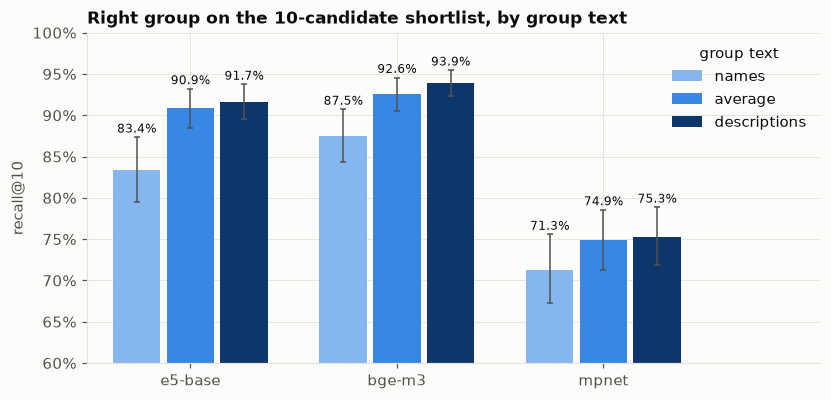

In [6]:
labelled = rows.assign(model=rows["model_short"] + " · " + rows["variant"])
ci = company_bootstrap_ci(labelled, K).set_index("model")
table = pd.DataFrame({v: [ci.loc[f"{short(m)} · {v}", "recall"] for m in models] for v in VARIANTS}, index=[short(m) for m in models])
display(table.style.format("{:.1%}").set_caption(f"recall@{K} on dev"))

fig, ax = plt.subplots(figsize=(8.6, 3.9))
width = 0.26
for j, v in enumerate(VARIANTS):
    for i, m in enumerate(models):
        r = ci.loc[f"{short(m)} · {v}"]
        x = i + (j - 1) * width
        ax.bar(x, r["recall"], width - 0.03, color=VARIANT_COLORS[v], label=v if i == 0 else None)
        ax.errorbar(x, r["recall"], yerr=[[r["recall"] - r["low"]], [r["high"] - r["recall"]]], color=INK_2, lw=1, capsize=2)
        ax.annotate(f"{r['recall']:.1%}", (x, r["high"]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_xticks(range(len(models)), [short(m) for m in models])
ax.set_ylim(0.6, 1.0)
ax.set_xlim(-0.5, len(models) - 0.5 + 0.55)  # room on the right for the legend, clear of the bars
ax.yaxis.set_major_formatter(pct())
ax.set_ylabel(f"recall@{K}")
ax.set_title(f"Right group on the {K}-candidate shortlist, by group text", loc="left")
ax.legend(title="group text", loc="upper right", frameon=False)
plt.show()

## 5. Where the gain comes from (bge-m3)

The paired differences use the same company resamples for both group texts, so the luck of which companies were drawn cancels out.

In [7]:
b = labelled[labelled.model.str.startswith("bge-m3")]
out = []
for src in ["all", "rules", "llm"]:
    part = b if src == "all" else b[b.source == src]
    rec = {v: (part[part.variant == v].gold_rank <= K).mean() for v in VARIANTS}
    row = {"accounts": int((part.variant == "names").sum()), **{f"recall@{K} {v}": rec[v] for v in VARIANTS}}
    for v in ["average", "descriptions"]:
        d, lo, hi = paired_difference(part, f"bge-m3 · {v}", "bge-m3 · names", K)
        row[f"{v} − names"] = f"{d * 100:+.1f} pts ({lo * 100:+.1f} to {hi * 100:+.1f})"
    out.append(pd.Series(row, name=src))
display(pd.DataFrame(out).style.format({f"recall@{K} {v}": "{:.1%}" for v in VARIANTS}))

,accounts,recall@10 names,recall@10 average,recall@10 descriptions,average − names,descriptions − names
all,3500,87.5%,92.6%,93.9%,+5.0 pts (+3.5 to +6.6),+6.3 pts (+4.4 to +8.3)
rules,2000,99.2%,99.4%,99.0%,+0.1 pts (-0.1 to +0.4),-0.3 pts (-0.8 to +0.1)
llm,1500,71.9%,83.5%,87.1%,+11.5 pts (+9.3 to +13.9),+15.2 pts (+12.7 to +17.7)


- **The whole gain is on the LLM-written accounts:** +11.5 points for `average` (interval +9.3 to +13.9), +15.2 for descriptions alone.
- **Rule-based accounts** were already at 99% and stay there: their names *are* the official names, with noise.
- Every language gains with `average`, by 3.4 (mixed) to 6.2 (en) points:

In [8]:
by_lang = b.assign(hit=b.gold_rank <= K).pivot_table(index="language", columns="variant", values="hit", aggfunc="mean")[VARIANTS]
by_lang["n"] = b[b.variant == "names"].groupby("language").size()
display(by_lang.sort_values("n", ascending=False).style.format({v: "{:.1%}" for v in VARIANTS}).set_caption(f"bge-m3 recall@{K} by language"))

variant,names,average,descriptions,n
language,,,,
en,88.9%,95.1%,97.1%,900
fr,86.7%,91.1%,93.0%,900
mixed,90.1%,93.5%,94.0%,850
nl,84.5%,90.5%,91.3%,850


How deep the shortlist must go with each group text:

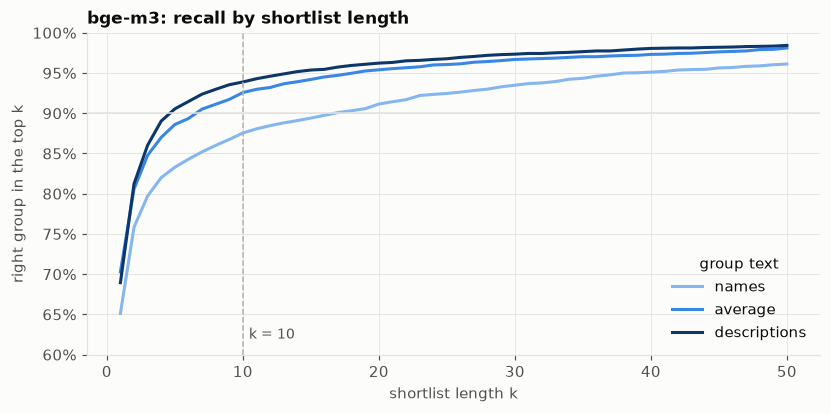

shortest k with recall >= 90%: {'names': 17, 'average': 7, 'descriptions': 5}
llm: shortest k with recall >= 90%: {'names': 45, 'average': 21, 'descriptions': 15}


In [9]:
ks = list(range(1, 51))
curves = pd.DataFrame({v: recall_curve(bge[bge.variant == v], ks).iloc[:, 0] for v in VARIANTS})
fig, ax = plt.subplots(figsize=(8.6, 3.8))
for v in VARIANTS:
    ax.plot(ks, curves[v], color=VARIANT_COLORS[v], lw=2, label=v)
ax.axvline(K, color=MUTED, lw=1, ls="--")
ax.annotate(f"k = {K}", (K, 0.62), xytext=(4, 0), textcoords="offset points", color=INK_2, fontsize=9)
ax.axhline(0.9, color=GRID, lw=1)
ax.set_xlabel("shortlist length k")
ax.set_ylabel("right group in the top k")
ax.yaxis.set_major_formatter(pct())
ax.set_ylim(0.6, 1.0)
ax.set_title("bge-m3: recall by shortlist length", loc="left")
ax.legend(title="group text", frameon=False, loc="lower right")
plt.show()
need = {v: next(k for k in ks if curves.loc[k, v] >= 0.9) for v in VARIANTS}
print("shortest k with recall >= 90%:", need)
for src in ["llm"]:
    sub = bge[bge.source == src]
    print(f"{src}: shortest k with recall >= 90%:", {v: next((k for k in range(1, 191) if ((sub[sub.variant == v].gold_rank <= k).mean() >= 0.9)), None) for v in VARIANTS})

Notebook 08 found that reaching 90% recall with names only would take a shortlist of **17**, and **45** for the LLM-written accounts. With `average` it takes **7** and **21**. So the plan's k = 10 now clears 90% overall without lengthening the shortlist. For the LLM-written accounts the same check gives 83.5%: still the weak spot, and the reason Task 3.5 also tries k = 20.

## 6. Which accounts moved onto the shortlist, and which fell off

From names only to the chosen `average`, for bge-m3:

In [10]:
w = bge.pivot_table(index="account_id", columns="variant", values="gold_rank")
meta = bge[bge.variant == "names"].set_index("account_id")[["name", "source", "language", "target_code"]]
w = meta.join(w)
moved_on = w[(w.names > K) & (w.average <= K)]
fell_off = w[(w.names <= K) & (w.average > K)]
counts = pd.DataFrame({"moved on": moved_on.source.value_counts(), "fell off": fell_off.source.value_counts()}).fillna(0).astype(int)
counts.loc["total"] = counts.sum()
display(counts)

,moved on,fell off
source,,
llm,177,4
rules,4,1
total,181,5


From names only to `average`, **181 accounts moved onto the shortlist and 5 fell off**, nearly all of them LLM-written.

In [11]:
def named(df):
    df = df.assign(group=df.target_code.map(lambda c: f"{c} {by_code[c].name_en[:38]}"))
    return df[["name", "source", "group", "names", "average", "descriptions"]].astype({"names": int, "average": int, "descriptions": int})

print("Moved on (the 10 that climbed most):")
display(named(moved_on.assign(gain=moved_on.names - moved_on.average).sort_values("gain", ascending=False).head(10)))
print("Fell off (all of them, worst first):")
display(named(fell_off.sort_values("average", ascending=False)))

Moved on (the 10 that climbed most):


,name,source,group,names,average,descriptions
account_id,,,,,,
dev-c050-045,Impairment participations,llm,661 Amounts Written Off Financial Fixed As,93,6,4
dev-c056-031,Current account 2,llm,550 Cash at Bank - Credit Institutions,75,3,1
dev-c050-035,Current account 2,llm,550 Cash at Bank - Credit Institutions,75,3,1
dev-c061-000,Herwaard. meerw. deelneming,llm,122 Revaluation Surpluses on Financial Fix,73,10,2
dev-c055-000,Herwaard. meerw. deelneming,llm,122 Revaluation Surpluses on Financial Fix,73,10,2
dev-c064-005,R/C dochter,llm,281 Amounts Receivable From Affiliated Ent,66,7,4
dev-c050-018,Rent deposit paid - Gent Veldstraat shop,llm,418 Sundry Amounts Receivable - Cash Guara,66,9,1
dev-c050-027,Group insurance premiums payable,llm,459 Other Social Obligations,66,9,3
dev-c058-046,Dividenden deelnemingen,llm,750 Income From Financial Fixed Assets,65,9,4


Fell off (all of them, worst first):


,name,source,group,names,average,descriptions
account_id,,,,,,
dev-c062-010,Aménagement entrepôt Aalst,llm,221 Buildings,1,16,73
dev-c042-009,R/C Vastgoed BV (verbonden),llm,281 Amounts Receivable From Affiliated Ent,8,13,27
dev-c064-001,Uitgest. belasting kapitaalsubsidie,llm,168 Deferred Taxes,10,13,31
dev-c003-035,MOINS-VALUES SUR RÉALISATIONS,rules,641 Loss on Ordinary Disposal of Tangible,10,11,12
dev-c057-013,Cautionnement chantiers,llm,288 Cash Guarantees Paid,10,11,13


- **The climbers** are named in everyday words the official names lack:
  - "Current account 2" (a company's second bank account, 550) climbs from rank 75 to 3;
  - "WV dubieuze klanten" (*waardevermindering*, a write-down on doubtful customers, 409) from 58 to 5;
  - "Rent deposit paid" (418) from 66 to 9.
- **The 5 that fell off** were mostly near the edge already: 4 of them sat at rank 8 to 10. "Aménagement entrepôt Aalst" (221 *Buildings*) is the exception: it fell from rank 1 to 16 (73 with descriptions alone). Adding words to every group can push a lucky exact match down as well as up.

## 7. The second test: what the embeddings baseline can auto-map

Recall is only the ceiling. The plan also judges the group text by the **embeddings baseline** of notebook 10: its pick is the top candidate, and it auto-maps when the calibrated confidence reaches the threshold for 98% precision. The confidence is calibrated on two numbers: the top score and its lead over the runner-up (notebook 09).

Below is the same calibration as `python -m d1.mapper.train` (out of fold by company, then the stricter of the two thresholds), run on each group text's saved scores:

In [12]:
def baseline(part):
    X = np.column_stack([part.top1_score, part.top1_score - part.top2_score])
    y = (part.gold_rank == 1).to_numpy()
    g = part.company_id.to_numpy()
    oof = cross_fit_probs(X, y, folds=5, seed=0, groups=g)
    p = Calibrator().fit(X, y).predict(X)
    t = stricter_threshold(choose_threshold(oof, y), choose_threshold(p, y))
    return y, p >= t, t

res = []
for v in VARIANTS:
    part = bge[bge.variant == v].reset_index(drop=True)
    y, auto, t = baseline(part)
    r = {"top-1": y.mean(), "threshold": t, "auto-mapped": auto.mean(), "precision": y[auto].mean()}
    for src in ["rules", "llm"]:
        s = (part.source == src).to_numpy()
        r[f"{src}: auto-mapped"] = auto[s].mean()
        r[f"{src}: precision"] = y[auto & s].mean()
    res.append(pd.Series(r, name=v))
res = pd.DataFrame(res)
display(res.style.format({c: "{:.1%}" for c in res.columns if c != "threshold"} | {"threshold": "{:.3f}"}))
saved = json.loads((REPO_ROOT / "artifacts" / "methods" / "embeddings" / "dev_summary.json").read_text())
print(f"saved embeddings artifact (group_text: {config.models.mapping.group_text}): auto-mapped {saved['auto_share']:.1%} at {saved['auto_precision']:.1%}")

,top-1,threshold,auto-mapped,precision,rules: auto-mapped,rules: precision,llm: auto-mapped,llm: precision
names,65.1%,0.954,21.4%,98.3%,34.8%,99.7%,3.6%,79.6%
average,70.3%,0.928,32.1%,98.0%,49.9%,99.3%,8.4%,88.1%
descriptions,68.9%,0.944,21.1%,98.2%,30.7%,99.7%,8.2%,91.1%


saved embeddings artifact (group_text: average): auto-mapped 32.1% at 98.0%


Why do descriptions alone auto-map no more than names only (21.1% against 21.4%), though their top-1 is higher? The overall top-1 hides a split by source:

In [13]:
top1 = pd.DataFrame({v: {src: (bge[(bge.variant == v) & (bge.source == src)].gold_rank == 1).mean() for src in ["rules", "llm"]} for v in VARIANTS}).T
top1["rule-based picks wrong"] = [int(((bge.variant == v) & (bge.source == "rules") & (bge.gold_rank != 1)).sum()) for v in VARIANTS]
display(top1.style.format({"rules": "{:.1%}", "llm": "{:.1%}"}).set_caption("bge-m3 top-1 by source"))

,rules,llm,rule-based picks wrong
names,88.9%,33.3%,221
average,90.0%,44.0%,200
descriptions,84.6%,48.1%,308


Descriptions alone make the **rule-based** picks worse: 308 wrong instead of 221. Those names are the official names with noise, such as "Achts de march." for 604 *Purchases of Goods for Resale*. With a description on every group, a neighbouring group whose description shares a word can overtake the exact match. Those wrong picks come with high scores, so they sit among the confident accounts, and the threshold must rise to keep 98%.

`average` keeps the exact-name match at full weight in half the score. Rule-based top-1 goes *up* to 90.0%, and the LLM-written accounts still get the description's help.

The curve below shows it. Sort the accounts by calibrated confidence and auto-map from the top down. The line gives the precision of what has been auto-mapped so far. Where it drops below 98% is how far each group text can go. (The calibrator here is fitted on all of dev, for the picture. The thresholds in the table above are chosen the stricter way, as in `train.py`.)

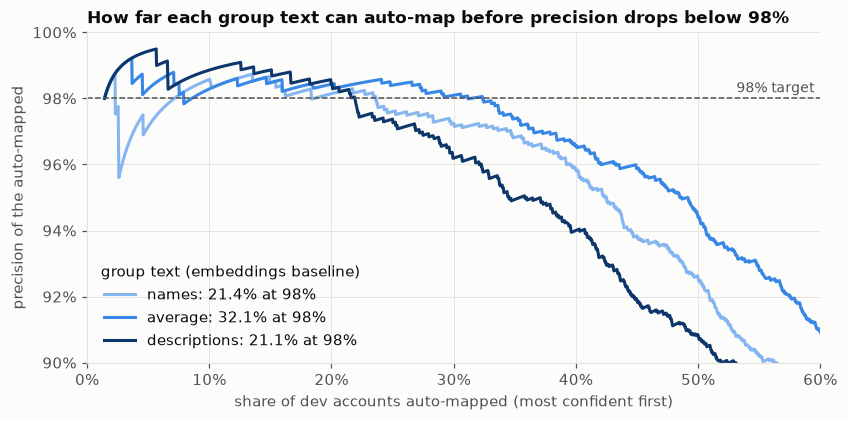

In [14]:
from d1.mapper.calibrate import precision_curve
fig, ax = plt.subplots(figsize=(8.6, 3.9))
for v in VARIANTS:
    part = bge[bge.variant == v]
    X = np.column_stack([part.top1_score, part.top1_score - part.top2_score])
    y = (part.gold_rank == 1).to_numpy()
    c = precision_curve(Calibrator().fit(X, y).predict(X), y)
    keep = c["support"] >= 50
    ax.plot(c["auto_share"][keep], c["precision"][keep], color=VARIANT_COLORS[v], lw=2, label=f"{v}: {res.loc[v, 'auto-mapped']:.1%} at 98%")
ax.axhline(TARGET := config.models.mapping.target_precision, color=INK_2, lw=1, ls="--")
ax.annotate("98% target", (0.595, TARGET), xytext=(0, 4), textcoords="offset points", ha="right", color=INK_2, fontsize=9)
ax.set_xlim(0, 0.6)
ax.set_ylim(0.90, 1.0)
ax.xaxis.set_major_formatter(pct())
ax.yaxis.set_major_formatter(pct())
ax.set_xlabel("share of dev accounts auto-mapped (most confident first)")
ax.set_ylabel("precision of the auto-mapped")
ax.set_title("How far each group text can auto-map before precision drops below 98%", loc="left")
ax.legend(title="group text (embeddings baseline)", frameon=False, loc="lower left")
plt.show()

- **`average`** stays at or above 98% the longest, up to 32.1% of dev.
- **Descriptions alone** drop below it first, at 21.1%, just before names only (21.4%). Those are the confident but wrong rule-based picks.

## 8. The decision

In [15]:
summary = pd.DataFrame({v: {f"recall@{K}": (bge[bge.variant == v].gold_rank <= K).mean(),
                            f"recall@{K}, LLM accounts": (bge[(bge.variant == v) & (bge.source == 'llm')].gold_rank <= K).mean(),
                            "top-1": res.loc[v, "top-1"], "baseline auto-mapped at 98%": res.loc[v, "auto-mapped"]} for v in VARIANTS}).T
display(summary.style.format("{:.1%}"))
print("config/models.yaml: embedding_model =", config.models.embedding_model, "| mapping.group_text =", config.models.mapping.group_text)

,recall@10,"recall@10, LLM accounts",top-1,baseline auto-mapped at 98%
names,87.5%,71.9%,65.1%,21.4%
average,92.6%,83.5%,70.3%,32.1%
descriptions,93.9%,87.1%,68.9%,21.1%


config/models.yaml: embedding_model = BAAI/bge-m3 | mapping.group_text = average


**Chosen: `group_text: average`**, with bge-m3, which is still the best model with every group text.
- **The shortlist ceiling** rises from 87.5% to 92.6% overall, and from 71.9% to 83.5% on the LLM-written accounts.
- **The embeddings baseline** auto-maps 32.1% of dev at 98.0%, up from 21.4%.
- **Descriptions alone** give the highest ceiling, 93.9%, but they hurt the rule-based picks, so the baseline auto-maps only 21.1%.

The Phase 3 methods choose among these shortlists, so the higher ceiling carries over to all of them. `python -m d1.mapper.train` reads `group_text` from the config. The trained baselines record it in `thresholds.json`, and the Mapper refuses to load a method calibrated on another group text.

**What to keep in mind:**
- **Chosen on dev, among three options.** Picking the best of three on dev adds a little optimism to the dev numbers. Test was not touched, and the final test run measures the chosen option once.
- **Sonnet and Opus are from the same family.** The descriptions are not written by the model that wrote the LLM accounts, and they never saw an account. But two models of one family may share some favourite wording, so part of the gain on LLM-written accounts may not carry over to real charts. The real company chart planned as a final check (a person's wording, not a model's) is where that shows.
- **The LLM-written dev labels are not hand-checked.** On test the hand check found 13% of them wrong, so every LLM-account number here is understated by a similar margin, for every option alike.